In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import h5py

In [2]:
plt.rcParams['text.usetex'] = True
plt.rcParams['text.latex.preamble'] = r'\usepackage{amsmath}\usepackage{amssymb}'
plt.rcParams['axes.edgecolor'] = '0.0'
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.size'] = 12

# Sizes
plt.rcParams['xtick.labelsize'] = 13
plt.rcParams['ytick.labelsize'] = 13
plt.rcParams['legend.fontsize'] = 13
plt.rcParams['axes.titlesize'] = 15
plt.rcParams['axes.labelsize'] = 15
plt.rcParams['axes.linewidth'] = 1.5
plt.rcParams['lines.linewidth'] = 2.2

# Tick parameters
plt.rcParams['xtick.top'] = 'False'
plt.rcParams['xtick.bottom'] = 'True'
plt.rcParams['xtick.minor.visible'] = 'True'
plt.rcParams['xtick.direction'] = 'out'
plt.rcParams['ytick.left'] = 'True'
plt.rcParams['ytick.right'] = 'False'
plt.rcParams['ytick.minor.visible'] = 'True'
plt.rcParams['ytick.direction'] = 'out'

plt.rcParams['xtick.major.width'] = 1.5
plt.rcParams['xtick.minor.width'] = 1
plt.rcParams['xtick.major.size'] = 3
plt.rcParams['xtick.minor.size'] = 9/4
plt.rcParams['ytick.major.width'] = 1.5
plt.rcParams['ytick.minor.width'] = 1
plt.rcParams['ytick.major.size'] = 3
plt.rcParams['ytick.minor.size'] = 9/4

In [3]:
df_props = pd.read_csv("host_props.csv")
df_reliable = pd.read_csv('all_parameters_reliable.csv').rename(columns={'objname':'transient'})
df_ddlr = pd.read_csv('titan_ddlr.csv').rename(columns={'objname':'transient'})
df_all = pd.read_csv('titan_snia.csv').rename(columns={'objname':'transient'})
print(len(df_props))
df_props = df_props.merge(df_ddlr[['transient', 'd_dlr']], on='transient', how='left')
df_props = df_props.merge(df_all[['transient','class_flag']], on='transient', how='left')
df_props = df_props[df_props['transient'].isin(df_reliable['transient']) & df_props['d_dlr'].le(10)]
df_props = df_props[df_props['class_flag'].eq(1)]

print(len(df_props))

9361
6983


In [6]:
h5_filenames = [
    'SN_age_samples_40Myr_slope-1.00.h5',
    'SN_age_samples_40Myr_slope-1.07.h5',
    'SN_age_samples_40Myr_slope-1.13.h5',
    'SN_age_samples_300Myr_slope-1.00.h5',
    'SN_age_samples_300Myr_slope-1.07.h5',
    'SN_age_samples_300Myr_slope-1.13.h5',
]


lowmass_Q = df_props['stellar_mass_50'].le(10) & df_props['ssfr_50'].le(-11)
lowmass_SF = df_props['stellar_mass_50'].le(10) & df_props['ssfr_50'].gt(-10.5)
highmass_Q = df_props['stellar_mass_50'].gt(10) & df_props['ssfr_50'].le(-11)
highmass_SF = df_props['stellar_mass_50'].gt(10) & df_props['ssfr_50'].gt(-10.5)



for h5_filename in h5_filenames:
    list_of_CIDs = []
    with h5py.File(h5_filename, 'r') as f:
        keys = list(f.keys())
        first = f[keys[0]]
        list_of_age_samples = np.empty((len(keys),) + first.shape, dtype=np.float32)
        for i, key in enumerate(keys):
            list_of_CIDs.append(key)
            f[key].read_direct(list_of_age_samples[i])
            
    # limit dada to good CIDs only
    CIDs_good = df_props['transient'].values
    CID_mask = np.isin(list_of_CIDs, CIDs_good)
    list_of_age_samples = list_of_age_samples[CID_mask]
    list_of_CIDs = np.array(list_of_CIDs)[CID_mask]
    
    _pdf = list_of_age_samples[:,::10,:]
    _ev = list_of_age_samples.mean(axis=2)

    print('----------',h5_filename,'----------')
    # compute _pdf percentiles
    lower, median, upper = np.percentile(_pdf.flatten(), [16, 50, 84])
    print(f'PDF percentiles: {lower:.3f}, {median:.3f}, {upper:.3f}')
    lower, median, upper = np.percentile(_ev.flatten(), [16, 50, 84])
    print(f'EV percentiles : {lower:.3f}, {median:.3f}, {upper:.3f}')
    mean = _pdf.flatten().mean()
    print('PDF mean:', mean)
    
    # compute mode and percentiles for each subsample
    def compute_mode_and_percentiles(ev,mask=None):
        if mask is not None:
            CID_mask = np.isin(list_of_CIDs, df_props['transient'][mask])
            ev = ev[CID_mask].mean(axis=0)
        percentiles = np.percentile(ev.flatten(), [16, 50, 84])
        return percentiles  

    # lowmass_Q_percentiles = compute_mode_and_percentiles(_ev, lowmass_Q)
    # lowmass_SF_percentiles = compute_mode_and_percentiles(_ev, lowmass_SF)
    highmass_Q_percentiles = compute_mode_and_percentiles(_ev, highmass_Q)
    highmass_SF_percentiles = compute_mode_and_percentiles(_ev, highmass_SF)
    diff = highmass_Q_percentiles[1] - highmass_SF_percentiles[1]
    diff_error = np.sqrt((highmass_Q_percentiles[2] - highmass_Q_percentiles[0])**2 + (highmass_SF_percentiles[2] - highmass_SF_percentiles[0])**2)
    
    slope = 0.03
    slope_err = 0.004
    HR_diff = slope * diff
    HR_diff_err = np.sqrt((slope_err * diff)**2 + (slope * diff_error)**2)
    print(f'HR diff: {HR_diff:.3f} +/- {HR_diff_err:.3f}')

---------- SN_age_samples_40Myr_slope-1.00.h5 ----------
PDF percentiles: 0.247, 2.203, 8.041
EV percentiles : 1.539, 3.260, 5.988
PDF mean: 3.6804578
HR diff: 0.095 +/- 0.013
---------- SN_age_samples_40Myr_slope-1.07.h5 ----------
PDF percentiles: 0.187, 1.863, 7.739
EV percentiles : 1.380, 2.977, 5.730
PDF mean: 3.4560707
HR diff: 0.099 +/- 0.013
---------- SN_age_samples_40Myr_slope-1.13.h5 ----------
PDF percentiles: 0.152, 1.596, 7.469
EV percentiles : 1.254, 2.732, 5.489
PDF mean: 3.2611327
HR diff: 0.102 +/- 0.014
---------- SN_age_samples_300Myr_slope-1.00.h5 ----------
PDF percentiles: 0.718, 3.201, 8.536
EV percentiles : 2.056, 3.937, 6.638
PDF mean: 4.275534
HR diff: 0.075 +/- 0.010
---------- SN_age_samples_300Myr_slope-1.07.h5 ----------
PDF percentiles: 0.679, 2.950, 8.321
EV percentiles : 1.924, 3.741, 6.523
PDF mean: 4.127023
HR diff: 0.078 +/- 0.011
---------- SN_age_samples_300Myr_slope-1.13.h5 ----------
PDF percentiles: 0.649, 2.746, 8.142
EV percentiles : 1.816, 3

In [9]:
HR_diff

array([0.09482454, 0.09522254, 0.09559912])

In [4]:
list_of_CIDs = []
# with h5py.File("SN_age_samples_40Myr_slope-1.00.h5", "r") as f:
# with h5py.File("SN_age_samples_40Myr_slope-1.13.h5", "r") as f:
# with h5py.File("SN_age_samples_300Myr_slope-1.00.h5", "r") as f:
# with h5py.File("SN_age_samples_300Myr_slope-1.13.h5", "r") as f:
# with h5py.File("SN_age_samples_300Myr_slope-1.07.h5", "r") as f:
with h5py.File("SN_age_samples_40Myr_slope-1.07.h5", "r") as f:
    keys = list(f.keys())
    first = f[keys[0]]
    list_of_age_samples = np.empty((len(keys),) + first.shape, dtype=np.float32)
    for i, key in enumerate(keys):
        list_of_CIDs.append(key)
        f[key].read_direct(list_of_age_samples[i])
  

In [5]:
# limit dada to good CIDs only
CIDs_good = df_props['transient'].values
CID_mask = np.isin(list_of_CIDs, CIDs_good)
list_of_age_samples = list_of_age_samples[CID_mask]
list_of_CIDs = np.array(list_of_CIDs)[CID_mask]

In [6]:
_pdf = list_of_age_samples[:,::10,:]
_ev = list_of_age_samples.mean(axis=2)

<>:27: SyntaxWarning: invalid escape sequence '\%'
<>:27: SyntaxWarning: invalid escape sequence '\%'
/tmp/ipykernel_2169619/1615926542.py:27: SyntaxWarning: invalid escape sequence '\%'
  plt.hist(mean_ages_CC, bins=bins,histtype='step',label='SF + 8\% Q')


Text(0.5, 0, 'Mean progenitor age for SH0ES HF (Gyr)')

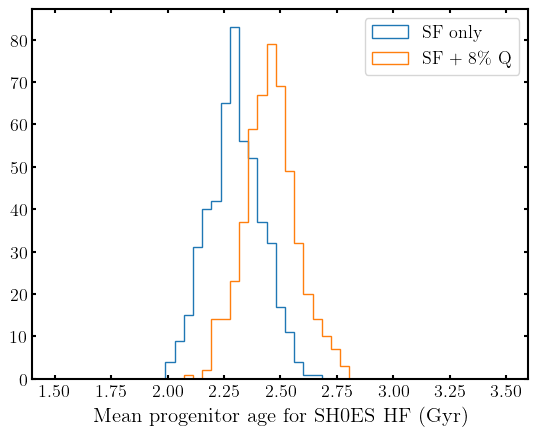

In [8]:
# CID_mask = np.isin(list_of_CIDs, df_props['transient'][mask])
# ev = _ev[CID_mask].mean(axis=0)

lowmass_Q = df_props['stellar_mass_50'].le(10) & df_props['ssfr_50'].le(-11)
lowmass_SF = df_props['stellar_mass_50'].le(10) & df_props['ssfr_50'].gt(-10.5)
highmass_Q = df_props['stellar_mass_50'].gt(10) & df_props['ssfr_50'].le(-11)
highmass_SF = df_props['stellar_mass_50'].gt(10) & df_props['ssfr_50'].gt(-10.5)

lmSF_CID_mask = np.isin(list_of_CIDs, df_props['transient'][lowmass_SF])
hmSF_CID_mask = np.isin(list_of_CIDs, df_props['transient'][highmass_SF])
ev_lmSF = _ev[lmSF_CID_mask]
ev_hmSF = _ev[hmSF_CID_mask]
# total SNe: 277 HF
# 8% from quiescent, 92% from star-forming
mean_ages_CC = []
mean_ages_HF = []
pct_hm_CC = 65
pct_hm_HF = 45
for _ in range(500):
    CC_ages = np.concatenate([np.random.choice(ev_hmSF.flatten(),size=pct_hm_CC),np.random.choice(ev_lmSF.flatten(),size=100-pct_hm_CC)])
    HF_ages = np.concatenate([np.random.choice(ev_hmSF.flatten(),size=pct_hm_HF),np.random.choice(ev_lmSF.flatten(),size=100-pct_hm_HF)])
    mean_ages_CC.append(np.mean(CC_ages))
    mean_ages_HF.append(np.mean(HF_ages))
    
bins = np.linspace(1.5,3.5,50)
plt.hist(mean_ages_HF, bins=bins,histtype='step',label='SF only')
plt.hist(mean_ages_CC, bins=bins,histtype='step',label='SF + 8\% Q')
plt.gca().tick_params(direction='in', top=True, right=True)
plt.legend()
plt.gca().minorticks_off()
plt.xlabel('Mean progenitor age for SH0ES HF (Gyr)')

In [10]:
np.mean(mean_ages_HF) -  np.mean(mean_ages_CC)

np.float32(-0.15816069)

In [ ]:
np.mean(mean_ages_with_contam)-np.mean(mean_ages)

np.float32(0.2534988)

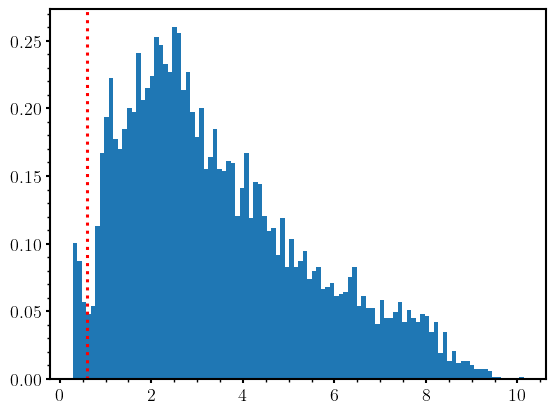

In [34]:
plt.hist(_ev.mean(axis=1), bins=100, density=True);
plt.axvline(0.6,c='r',ls=':')

In [38]:
(_ev.mean(axis=1) < 0.6).sum()/_ev.mean(axis=1).shape[0]

np.float64(0.025347271946154947)

In [21]:
np.median(_pdf)

np.float32(3.3559008)

In [19]:
age_bins = np.arange(0, 14, 0.01)
bin_centers = (age_bins[:-1] + age_bins[1:]) / 2
counts,_ = np.histogram(_ev.mean(axis=0).flatten(), bins=age_bins)
mode = bin_centers[np.argmax(counts)]
mode, np.percentile(_ev.mean(axis=0).flatten(), [16, 50, 84])

(np.float64(4.345000000000001), array([4.33908577, 4.34901834, 4.35886477]))

In [20]:

lowmass_Q = df_props['stellar_mass_50'].le(10) & df_props['ssfr_50'].le(-11)
lowmass_SF = df_props['stellar_mass_50'].le(10) & df_props['ssfr_50'].gt(-10.5)
highmass_Q = df_props['stellar_mass_50'].gt(10) & df_props['ssfr_50'].le(-11)
highmass_SF = df_props['stellar_mass_50'].gt(10) & df_props['ssfr_50'].gt(-10.5)

# compute mode and percentiles for each subsample
def compute_mode_and_percentiles(ev,mask=None):
    if mask is not None:
        CID_mask = np.isin(list_of_CIDs, df_props['transient'][mask])
        ev = ev[CID_mask].mean(axis=0)
    age_bins = np.arange(0, 14, 0.01)
    bin_centers = (age_bins[:-1] + age_bins[1:]) / 2
    counts,_ = np.histogram(ev.flatten(), bins=age_bins)
    mode = bin_centers[np.argmax(counts)]
    percentiles = np.percentile(ev.flatten(), [16, 50, 84])
    return mode, percentiles
lowmass_Q_mode, lowmass_Q_percentiles = compute_mode_and_percentiles(_ev, lowmass_Q)
lowmass_SF_mode, lowmass_SF_percentiles = compute_mode_and_percentiles(_ev, lowmass_SF)
highmass_Q_mode, highmass_Q_percentiles = compute_mode_and_percentiles(_ev, highmass_Q)
highmass_SF_mode, highmass_SF_percentiles = compute_mode_and_percentiles(_ev, highmass_SF)

print("Low-mass Q: mode =", lowmass_Q_mode, "percentiles =", lowmass_Q_percentiles)
print("Low-mass SF: mode =", lowmass_SF_mode, "percentiles =", lowmass_SF_percentiles)
print("High-mass Q: mode =", highmass_Q_mode, "percentiles =", highmass_Q_percentiles)
print("High-mass SF: mode =", highmass_SF_mode, "percentiles =", highmass_SF_percentiles)

Low-mass Q: mode = 6.745 percentiles = [6.67263536 6.75075078 6.82171848]
Low-mass SF: mode = 2.875 percentiles = [2.85769048 2.87317944 2.88779702]
High-mass Q: mode = 6.345000000000001 percentiles = [6.31633072 6.34062552 6.36444029]
High-mass SF: mode = 3.805 percentiles = [3.79645176 3.81326485 3.83094743]


In [194]:
highmass_Q_percentiles[1]-highmass_SF_percentiles[1]

np.float64(2.682159662246704)

In [4]:
ylocs = [1.8,-0.2,-2.2,1.2,-0.8,-2.8]
xvals = [0.095,0.099,0.102,0.075,0.078,0.080]
xerrs = [0.013,0.013,0.014,0.010,0.011,0.011]
colors = ['darkgoldenrod','royalblue','seagreen',
          'darkgoldenrod','royalblue','seagreen',]
facecolors = [None,None,None,'w','w','w']

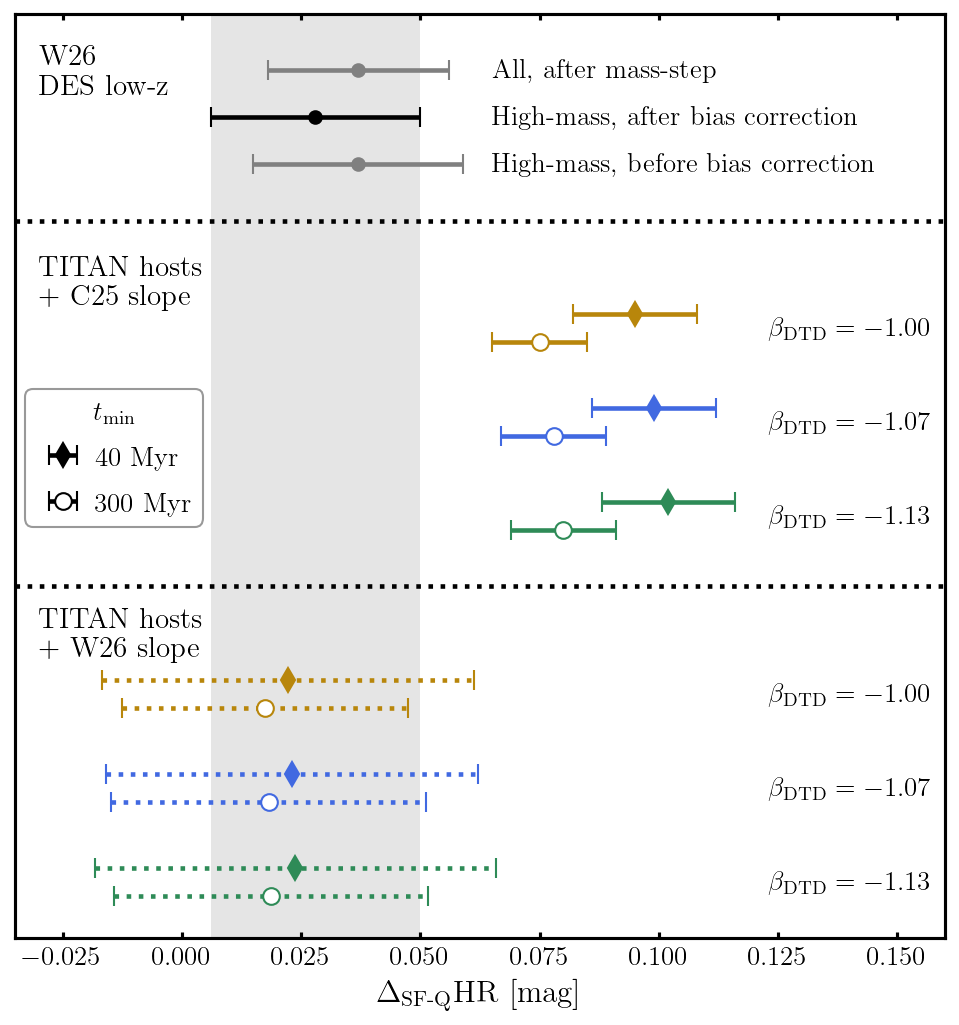

In [19]:
fig,ax = plt.subplots(1,1,figsize=(8,8),dpi=150)

ax.errorbar(0.037, 7, xerr=0.019, fmt='o', capsize=5,color='gray')
ax.errorbar(0.028, 6, xerr=0.022, fmt='o', capsize=5,color='k')
ax.errorbar(0.037, 5, xerr=0.022, fmt='o', capsize=5,color='gray')
# ax.axvline(0.028, color='k', linestyle='--')
ax.axvspan(0.028-0.022, 0.028+0.022, color='gray', alpha=0.2,lw=0)
ax.text(0.065,7, 'All, after mass-step', fontsize=13, va='center')
ax.text(0.065,6, 'High-mass, after bias correction', fontsize=13, va='center')
ax.text(0.065,5, 'High-mass, before bias correction', fontsize=13, va='center')
ax.text(-0.03,6.5, 'W26\nDES low-z',fontsize=14, fontweight='bold')

ax.axhline(3.8,ls=':',c='k') #------------------------


ax.text(-0.03,2., 'TITAN hosts\n+ C25 slope',fontsize=14, fontweight='bold')

# legend for cutoff time
ax.errorbar(-1, 1.1, xerr=0.004, fmt='d', capsize=5,color='k',ms=8,label='40 Myr')
ax.errorbar(-1, 0.1, xerr=0.004, fmt='o', capsize=5,color='k',mfc='w',ms=8, label='300 Myr')
leg = ax.legend(loc='upper left', bbox_to_anchor=(0.005, 0.6), frameon=True,
                title=r'$t_\text{min}$', title_fontsize=13,
                handletextpad=0.2, borderpad=0.1, labelspacing=0.8)
leg.get_frame().set_boxstyle('round')
leg.get_frame().set_edgecolor('gray') 

ylocs = [1.8,-0.2,-2.2,1.2,-0.8,-2.8]
xvals = [0.095,0.099,0.102,0.075,0.078,0.080]
xerrs = [0.013,0.013,0.014,0.010,0.011,0.011]
colors = ['darkgoldenrod','royalblue','seagreen',
          'darkgoldenrod','royalblue','seagreen',]
facecolors = [None,None,None,'w','w','w']
markers = ['d','d','d','o','o','o']
for yloc, xval, xerr, color, mfc, marker in zip(ylocs, xvals, xerrs, colors, facecolors, markers):
    ax.errorbar(xval, yloc, xerr=xerr, fmt=marker, capsize=5, color=color, ms=8, mec=color, mfc=mfc)
label_xloc = 0.14
ax.text(label_xloc,1.5, r'$\beta_\text{DTD}=-1.00$', fontsize=13, va='center', ha='center')
ax.text(label_xloc,-0.5, r'$\beta_\text{DTD}=-1.07$', fontsize=13, va='center', ha='center')
ax.text(label_xloc,-2.5, r'$\beta_\text{DTD}=-1.13$', fontsize=13, va='center', ha='center')

ax.axhline(-4,ls=':',c='k') #------------------------
ax.text(-0.03,-5.5, 'TITAN hosts\n+ W26 slope',fontsize=14, fontweight='bold')
ax.text(label_xloc,1.5-7.8, r'$\beta_\text{DTD}=-1.00$', fontsize=13, va='center', ha='center')
ax.text(label_xloc,-0.5-7.8, r'$\beta_\text{DTD}=-1.07$', fontsize=13, va='center', ha='center')
ax.text(label_xloc,-2.5-7.8, r'$\beta_\text{DTD}=-1.13$', fontsize=13, va='center', ha='center')

for yloc, xval, xerr, color, mfc, marker in zip(ylocs, xvals, xerrs, colors, facecolors, markers):
    eb = ax.errorbar(xval/0.03*0.007, yloc-7.8, xerr=xerr/0.004*0.012, fmt=marker, capsize=5, color=color, ms=8, mec=color, mfc=mfc,linestyle=':')
    eb[-1][0].set_linestyle(':') 
label_xloc = 0.14
# ax.errorbar(3.32*0.007, -6, xerr=3.32*0.013,fmt='d',ms=8,capsize=5,mec='indigo',c='indigo')
# ax.errorbar(2.61*0.007, -7, xerr=2.61*0.013,fmt='o',ms=8,capsize=5,mec='indigo',mfc='w',c='indigo')

ax.set_xlim(-0.035,0.16)
ax.set_ylim(-11.5,8.2)
ax.minorticks_off()
ax.tick_params(direction='in', top=True, right=True)
ax.set_yticks([])
ax.set_xlabel(r'$\Delta_\text{SF-Q}\text{HR}$ [mag]', fontsize=15)
plt.savefig('figures/HR_separation_tests.pdf', bbox_inches='tight')

## WD sims

In [9]:
M1_M2_tau_ONe = np.load('../WDsim/M1_M2_tau_ONe.npy', allow_pickle=True).item()
M1_M2_tau_CO = np.load('../WDsim/M1_M2_tau_CO.npy', allow_pickle=True).item()
from matplotlib.colors import BoundaryNorm, LogNorm
from matplotlib.ticker import FixedLocator, FixedFormatter

x_uniques, y_uniques,Z_matrices = [],[],[]
for _data in [M1_M2_tau_ONe, M1_M2_tau_CO]:
    x,y,z = [],[],[]
    for (m1, m2), val in _data.items():
        x.append(float(m1))
        y.append(float(m2))
        z.append(float(val))
    x = np.array(x)
    y = np.array(y)
    z = np.array(z)

    # Get unique values for grid
    x_unique = np.sort(np.unique(x))
    y_unique = np.sort(np.unique(y))

    # Create 2D grid
    Z = np.full((len(y_unique), len(x_unique)), np.nan)

    for i, (m1, m2) in enumerate(zip(x, y)):
        xi = np.where(x_unique == m1)[0][0]
        yi = np.where(y_unique == m2)[0][0]
        Z[yi, xi] = z[i]
    x_uniques.append(x_unique)
    y_uniques.append(y_unique)
    Z_matrices.append(Z)
x_ONe = x_uniques[0]
y_ONe = y_uniques[0]
Z_ONe = Z_matrices[0]
x_CO = x_uniques[1]
y_CO = y_uniques[1]
Z_CO = Z_matrices[1]

/tmp/ipykernel_3857406/877594742.py:43: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=15,frameon=False)


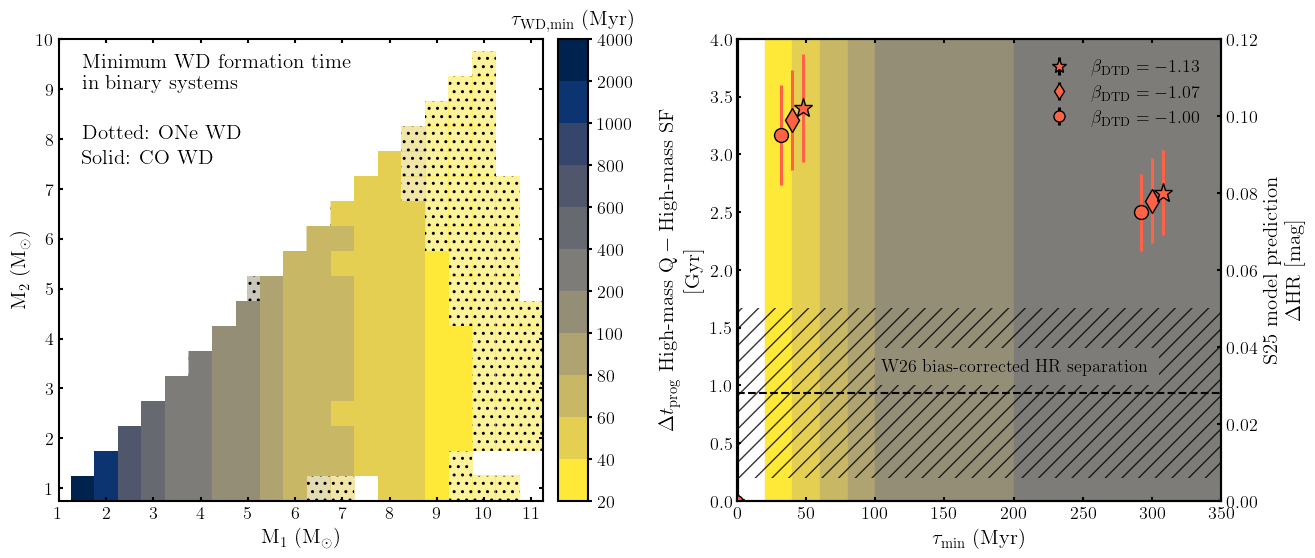

In [75]:
levels = [20, 40, 60, 80, 100, 200, 400, 600, 800, 1000, 2000, 4000]
norm = BoundaryNorm(levels, ncolors=256)


fig,axes = plt.subplots(1,2,figsize=(15,6))
plt.subplots_adjust(wspace=0.40)
######## sim results
cmap_WDsim = plt.get_cmap('cividis_r')
ax = axes[0]
im = ax.pcolor(x_ONe, y_ONe, Z_ONe, cmap=cmap_WDsim,
               shading='nearest', 
                   norm=norm,zorder=-1, alpha=0.5,hatch='..',rasterized=True,
                   linewidth=0,
                   edgecolor='none')

im = ax.pcolormesh(x_CO, y_CO, Z_CO, cmap=cmap_WDsim, shading='nearest', norm=norm,zorder=1)

# Add colorbar with custom ticks
pos = ax.get_position().bounds
cax = fig.add_axes([pos[0] + pos[2] + 0.01, pos[1], 0.02, pos[3]])
cbar = plt.colorbar(im, cax=cax)
cbar.set_ticks(levels)
cbar.set_ticklabels([f'{int(l)}' for l in levels])
cax.set_title(r'$\mathrm{\tau_{WD,min}~(Myr)}$', fontsize=15, pad=10)
# cbar.set_label(r'$\mathrm{\tau_{min}~(M{yr})}$')

ax.set_xticks([1,2,3,4,5,6,7,8,9,10,11])
ax.set_yticks([1,2,3,4,5,6,7,8,9,10])
ax.minorticks_off()
ax.tick_params(direction='in',top=True,right=True,labelsize=13)
ax.set_xlabel(r'$\mathrm{M_1~(M_{\odot})}$',fontsize=15)
ax.set_ylabel(r'$\mathrm{M_2~(M_{\odot})}$',fontsize=15)
cax.tick_params(labelsize=13)
ax.text(1.5,9.0,'Minimum WD formation time\nin binary systems', fontsize=15, fontweight='bold')
ax.text(1.5,8.0,'Dotted: ONe WD', fontsize=15)
ax.text(1.5,7.5,'Solid: CO WD', fontsize=15)
#ax.set_title('2D Color Plot (Custom Log Scale)', fontsize=14)

####### test results
ax = axes[1]
cmap = plt.get_cmap('inferno')

ax.legend(fontsize=15,frameon=False)
ax.set_xlim(0,350)
ax.set_ylim(0.,4.)
ax_twinx = ax.twinx()
_ylim = ax.get_ylim()
ax_twinx.set_ylim(_ylim[0]*0.03, _ylim[1]*0.03)
ax_twinx.set_ylabel(r'$\mathrm{S25\ model\ prediction}$'+'\n'+r'$\Delta$HR [mag]',fontsize=15)
# ax_twinx.set_yticks(np.arange(0.065, 0.12, 0.01))
ax_twinx.tick_params(direction='in',labelsize=13)
ax.tick_params(direction='in',top=True,labelsize=13)

for i in range(len(levels)-2):
    ax.axvspan(levels[i], levels[i+1], 
               color=cmap_WDsim(norm(levels[i])), alpha=1, zorder=-1)
# ax.text(40,3.6,'Stellar Model Predictions', ha='center',va='bottom',rotation=90,fontsize=13)
ax.set_ylabel(r'$\Delta t_\mathrm{prog}\ \mathrm{High\text{-}mass\ Q - High\text{-}mass\ SF}$'+'\n'+'[Gyr]',fontsize=15)
ax.set_xlabel(r'$\tau_\mathrm{min}$ (Myr)',fontsize=15)
ax.minorticks_off()
ax_twinx.minorticks_off()

delta_HR_vals = [0.095,0.099,0.102,0.075,0.078,0.080]
delta_HR_errs = [0.013,0.013,0.014,0.010,0.011,0.011]
cutoff_locs = [40, 40, 40, 300, 300, 300]
markers = ['o','d','*','o','d','*']
x_offset = [-8,0,8,-8,0,8]
ms = [10,12,14,10,12,14]
for cutoff, delta_HR, delta_HR_err, marker,offset, size in zip(
    cutoff_locs, delta_HR_vals, delta_HR_errs, markers, x_offset, ms):
    ax_twinx.errorbar(cutoff+offset, delta_HR, xerr=0, yerr=delta_HR_err, 
                      fmt=marker, capsize=0, color='tomato', ms=size,mec='k',)#, mfc='w')#, mec=color)#, mfc='w')

ax_twinx.axhline(0.028, color='k', linestyle='--', lw=1.5)
ax_twinx.axhspan(0.028-0.022, 0.028+0.022, color='w', alpha=0.8,lw=0, hatch='//',zorder=10,
                 ec='k',fc='none',
                 rasterized=True)
ax_twinx.axvspan(100,200,ymin=0.25,ymax=0.33, color=cmap_WDsim(norm(110)), 
                 alpha=1,lw=0, hatch='//',zorder=10,)
ax_twinx.axvspan(200,305,ymin=0.25,ymax=0.33, color=cmap_WDsim(norm(300)), 
                 alpha=1,lw=0, hatch='//',zorder=10,)
ax_twinx.text(200, 0.0325, 'W26 bias-corrected HR separation', fontsize=13, va='bottom', ha='center',zorder=100)

ax_twinx.errorbar(0,0,yerr=1,c='k',mfc='tomato',fmt='*',label=r'$\beta_\text{DTD}=-1.13$',ms=10)
ax_twinx.errorbar(0,0,yerr=1,c='k',mfc='tomato',fmt='d',label=r'$\beta_\text{DTD}=-1.07$',ms=8)
ax_twinx.errorbar(0,0,yerr=1,c='k',mfc='tomato',fmt='o',label=r'$\beta_\text{DTD}=-1.00$',ms=8)
ax_twinx.legend(loc='upper right', bbox_to_anchor=(0.99, 0.99), frameon=False)

plt.savefig('figures/WDsim_and_S25_comparison.pdf', dpi=300, bbox_inches='tight')

In [24]:
6.08-3.44, 6.24-3.63

(2.64, 2.6100000000000003)

In [32]:
(_pdf.flatten()<6.5).sum()/(_pdf.flatten().size)

np.float64(0.7704738257839722)

In [44]:
0.004*3.3

0.0132

In [66]:
W26_latetype = ['2004ef', '2006az', '2007is', '2008gb', '2007ux', '2005eq',
       '2008ar', '2005hc', '2006ob', '2006te', '2005hj', '2008bz',
       '2003cq', '2007co', '2003fa', '2005iq', '2005ms', '2006oa',
       '2008050', '2005ir', '2008cf', '2005lz', '2001eh', '2008fr',
       '2001az', '2008051', '2007ae', '2008hj', '2003U', '2004L',
       '2009ad', '2005M', '2007bd', '2007jg', '2003kc', '2007sw',
       '2010ag', '2005na', '2006cq', '2004as', '2007kk', '2006mo',
       '2007su', '2010dt', '2007O', '2008Y', '2005ku', '2002hu', '2009do',
       '2007cq', '2006S', '2007kh', '2006lu', '2006cf', '2006gr',
       '2008gp', '2003it', '2001ah', '2009bv', '2016cck', '2017lm',
       '2016iyv', '2017po', '2016cxb', '2016eky', '2017ln', '2017yk',
       '2016glp', '2016hqf', '2016gmb', '2016grz', '2016ick', '2016hpx',
       '2017aaa', '2016ixf', '2016cvv', '2017azk', '2017cii', '2017adj',
       '2016blj', '2017hn', '2016hns', '2016aqs', '2017mf', '2016htm',
       '2017ms', '2016htn', '2016fbo']

W26_earlytype = ['2007nq', '2003iv', '2002he', '2006al', '2008gl', '2003ch',
       '2004gs', '2006on', '2003ic', '2006py', '2005eu', '2010dw',
       '2016afk', '2016bew', '2016aqb', '2016ayg', '2016esh', '2017wb',
       '2017zd', '2016K', '2017cju', '2016enx', '2016ajl', '2016aew',
       '2016aex', '2016cvw', '2016cyt', '2017cjv', '2016aud', '2017cpu',
       '2016cob', '2016cpy']

In [71]:
df_props['ssfr_50'].between(-11,-10.5).sum()/len(df_props)

np.float64(0.18385598141695703)

In [ ]:
plt.scatter(df_props[''],df_props['prog_age_50'],s=1,c='k')

In [81]:
_corr = []
_columns = df_props.columns
for col in _columns:
    # determine the correlation between col and prog_age_50
    if 'prog_age' in col:
        _corr.append(0)
        continue
    elif '50' in col:
        try:
            corr = df_props[col].corr(df_props['prog_age_50'])
            _corr.append(corr)
        except:
            _corr.append(None)
    else:
        _corr.append(None)

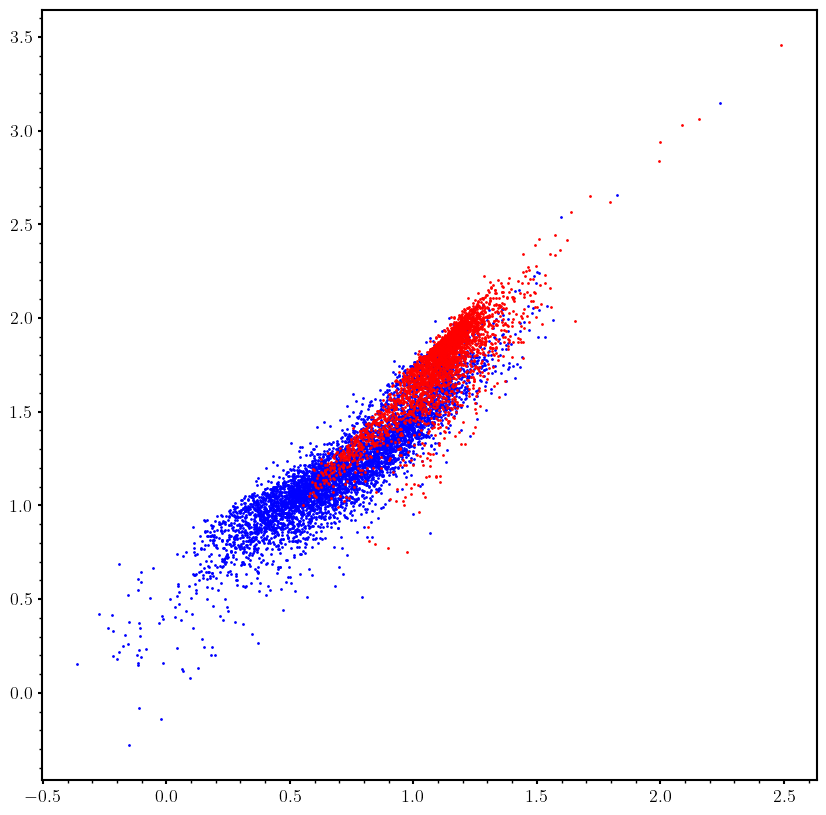

In [88]:
_young = df_props['prog_age_50'].le(4)
_old = df_props['prog_age_50'].gt(4)
plt.figure(figsize=(10,10),dpi=100)
plt.scatter(df_props.loc[_young, 'gz_colour_50'], df_props.loc[_young, 'uv_colour_50'], s=1, c='b')
plt.scatter(df_props.loc[_old, 'gz_colour_50'], df_props.loc[_old, 'uv_colour_50'], s=1, c='r')

In [90]:
df_props.columns

Index(['transient', 'stellar_mass_16', 'stellar_mass_50', 'stellar_mass_84',
       'sfr_16', 'sfr_50', 'sfr_84', 'ssfr_16', 'ssfr_50', 'ssfr_84',
       'iyer2019:metallicity_16', 'iyer2019:metallicity_50',
       'iyer2019:metallicity_84', 'mass_weighted_age_16',
       'mass_weighted_age_50', 'mass_weighted_age_84', 'dust:Av_16',
       'dust:Av_50', 'dust:Av_84', 'uv_colour_16', 'uv_colour_50',
       'uv_colour_84', 'vj_colour_16', 'vj_colour_50', 'vj_colour_84',
       'gz_colour_16', 'gz_colour_50', 'gz_colour_84', 'ps_g_mag_16',
       'ps_g_mag_50', 'ps_g_mag_84', 'ps_r_mag_16', 'ps_r_mag_50',
       'ps_r_mag_84', 'ps_i_mag_16', 'ps_i_mag_50', 'ps_i_mag_84',
       'ps_z_mag_16', 'ps_z_mag_50', 'ps_z_mag_84', 'ps_y_mag_16',
       'ps_y_mag_50', 'ps_y_mag_84', 'sdss_u_mag_16', 'sdss_u_mag_50',
       'sdss_u_mag_84', 'sdss_g_mag_16', 'sdss_g_mag_50', 'sdss_g_mag_84',
       'sdss_r_mag_16', 'sdss_r_mag_50', 'sdss_r_mag_84', 'sdss_i_mag_16',
       'sdss_i_mag_50', 'sdss_i_mag

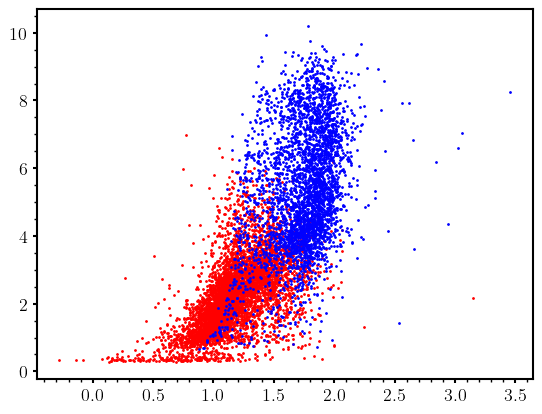

In [84]:
_s = df_props['ssfr_50'].gt(-10.5)
plt.scatter(df_props.loc[_s, 'uv_colour_50'], df_props.loc[_s, 'prog_age_50'], s=1, c='r')
plt.scatter(df_props.loc[~_s, 'uv_colour_50'], df_props.loc[~_s, 'prog_age_50'], s=1, c='b')

In [82]:
# top 5 correlated properties with prog_age_50
# replace None with 0 in _corr
_corr = [0 if c is None else c for c in _corr]
_corr = np.array(_corr)
_columns = np.array(_columns)
top5_indices = np.argsort(np.abs(_corr))[-5:]
top5_columns = _columns[top5_indices]
top5_correlations = _corr[top5_indices]
print("Top 5 correlated properties with prog_age_50:")
for col, corr in zip(top5_columns, top5_correlations):
    print(f"{col}: correlation = {corr:.3f}")

Top 5 correlated properties with prog_age_50:
vj_colour_50: correlation = 0.518
gz_colour_50: correlation = 0.678
uv_colour_50: correlation = 0.735
ssfr_50: correlation = -0.828
mass_weighted_age_50: correlation = 0.895


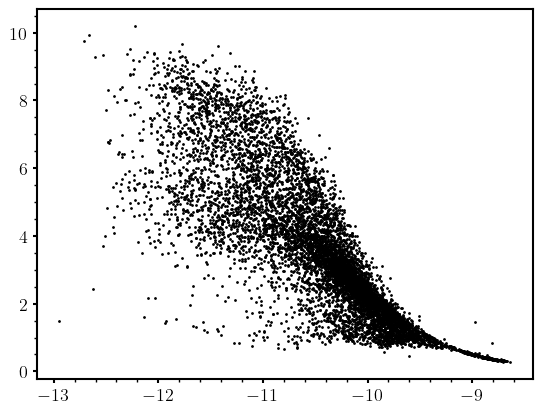

In [75]:
plt.scatter(df_props['ssfr_50'],df_props['prog_age_50'],s=1,c='k')

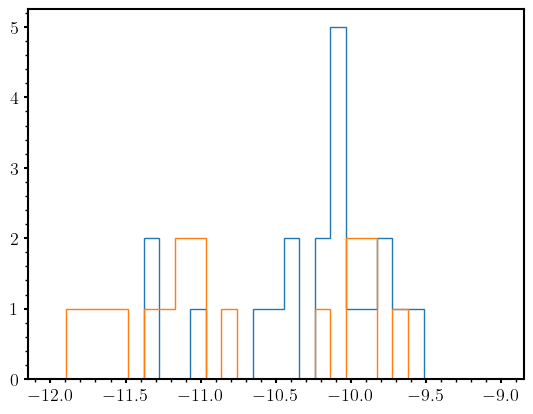

In [72]:
bins = np.linspace(-12,-9,30)
for _type in [W26_latetype, W26_earlytype]:
    plt.hist(df_props[df_props['transient'].isin(_type)]['ssfr_50'], bins=bins,histtype='step', density=False)

In [ ]:
df_props[df_props['transient'].eq('2016bey')]['ssfr_50']

4093   -10.463981
Name: ssfr_50, dtype: float64

In [64]:
'2017ns' in list_of_CIDs

True

In [56]:
slope = 0.007
slope_err = 0.013
sigma_diff = (3.3*slope - 0.037)/np.sqrt((3.3*slope_err)**2 + 0.019**2)
sigma_diff

np.float64(-0.29625407497582124)

In [48]:
(0.099-0.037)/np.sqrt(0.013**2 + 0.019**2)

np.float64(2.6931079051310305)

In [49]:
(0.099-0.028)/np.sqrt(0.022**2 + 0.013**2)

np.float64(2.778444704691655)

In [38]:
0.03*3.3

0.09899999999999999

In [22]:
np.mean(_pdf.flatten()), np.percentile(_pdf.flatten(), [16, 50, 84])

(np.float32(3.5441136), array([0.1959732 , 2.00193763, 7.85111141]))

<>:35: SyntaxWarning: invalid escape sequence '\%'
<>:36: SyntaxWarning: invalid escape sequence '\m'
<>:35: SyntaxWarning: invalid escape sequence '\%'
<>:36: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_1127008/3940579777.py:35: SyntaxWarning: invalid escape sequence '\%'
  _twinx.set_xticklabels([f'{p}\%' for p in np.arange(25,101,25)])
/tmp/ipykernel_1127008/3940579777.py:36: SyntaxWarning: invalid escape sequence '\m'
  _twinx.set_xlabel('Percentiles of $t_\mathrm{prog}$')


Text(0.5, 0.98, 'CUTOFF:300Myr, SLOPE:-1.07')

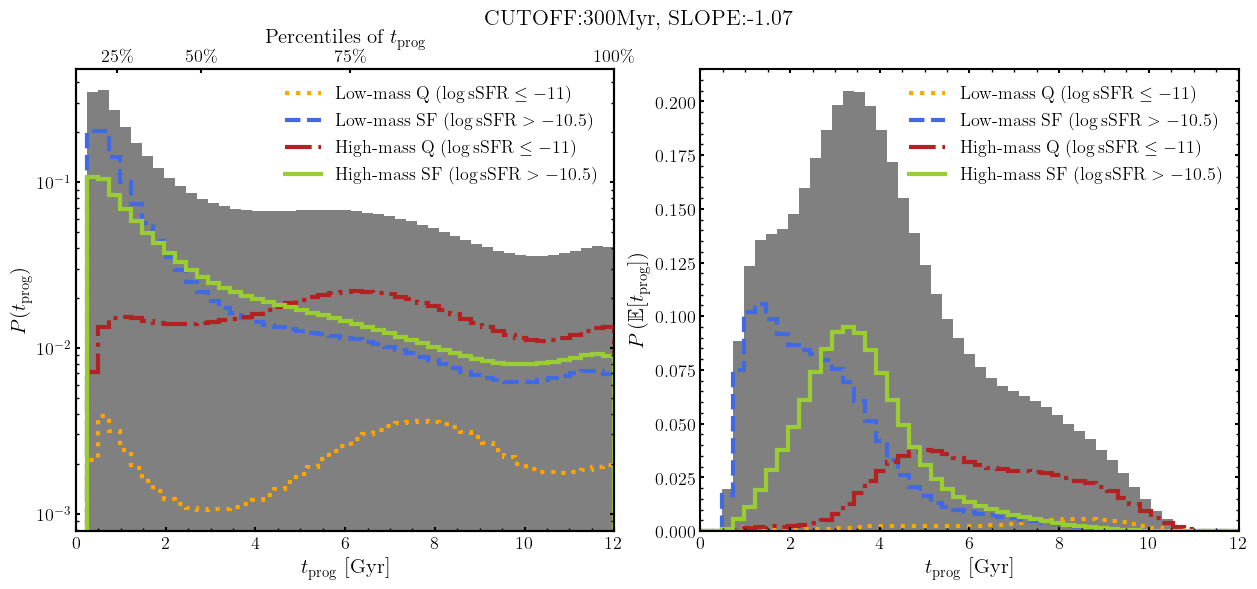

In [10]:
# split by sSFR (intermediate population removed)

lowmass_Q = df_props['stellar_mass_50'].le(10) & df_props['ssfr_50'].le(-11)
lowmass_SF = df_props['stellar_mass_50'].le(10) & df_props['ssfr_50'].gt(-10.5)
highmass_Q = df_props['stellar_mass_50'].gt(10) & df_props['ssfr_50'].le(-11)
highmass_SF = df_props['stellar_mass_50'].gt(10) & df_props['ssfr_50'].gt(-10.5)

names = [r"Low-mass Q ($\log\mathrm{sSFR} \le -11$)", r"Low-mass SF ($\log\mathrm{sSFR} > -10.5$)", r"High-mass Q ($\log\mathrm{sSFR} \le -11$)", r"High-mass SF ($\log\mathrm{sSFR} > -10.5$)"]
colors = ['orange','royalblue','firebrick','yellowgreen']
masks = [lowmass_Q, lowmass_SF, highmass_Q, highmass_SF]

fig,axes = plt.subplots(1,2,figsize=(15,6))
plt.subplots_adjust(wspace=0.16)
bins = np.linspace(0,12,50)

# normalize to density
counts_pdf, edges = np.histogram(np.ravel(_pdf), bins=bins)
counts_ev, _ = np.histogram(np.ravel(_ev), bins=bins)
norm1 = len(np.ravel(_pdf)) * np.diff(edges)
norm2 = len(np.ravel(_ev)) * np.diff(edges)
axes[0].stairs(counts_pdf/norm1, edges, color='gray',fill=True)
axes[1].stairs(counts_ev/norm2, edges, color='gray', fill=True)

for mask, name, color, ls in zip(masks, names, colors, [':', '--', '-.', '-']):
    CID_mask = np.isin(list_of_CIDs, df_props['transient'][mask])

    _counts_pdf = np.histogram(np.ravel(_pdf[CID_mask]), bins=bins)[0]
    _counts_ev = np.histogram(np.ravel(_ev[CID_mask]), bins=bins)[0]
    axes[0].stairs(_counts_pdf/norm1, edges, color=color, label=name,lw=3,ls=ls)
    axes[1].stairs(_counts_ev/norm2, edges, color=color, label=name,lw=3,ls=ls)

_twinx = axes[0].twiny()
_twinx.set_xlim(0,12)
_twinx.set_xticks(np.nanpercentile(_pdf, np.arange(25,101,25)))
_twinx.set_xticklabels([f'{p}\%' for p in np.arange(25,101,25)])
_twinx.set_xlabel('Percentiles of $t_\mathrm{prog}$')
_twinx.minorticks_off()
_twinx.set_yticks([])
_twinx.tick_params(direction='in')
axes[0].set_xlim(0,12)
axes[0].set_yscale('log')
axes[1].set_xlim(0,12)
axes[0].set_ylabel(r'$P(t_\mathrm{prog})$',fontsize=15)
axes[1].set_ylabel(r'$P\left(\mathbb{E}[t_\mathrm{prog}]\right)$',fontsize=15)
axes[0].legend(frameon=False);
axes[1].legend(frameon=False);

axes[0].tick_params(which='both', direction='in', top=False, right=True)
axes[1].tick_params(which='both', direction='in', top=True, right=True)
for ax in axes:
    ax.set_xlabel(r'$t_\mathrm{prog}$ [Gyr]',fontsize=15)
fig.suptitle(f'CUTOFF:300Myr, SLOPE:-1.07', fontsize=16)
# plt.savefig('figures/progenitor_age_histogram.pdf', bbox_inches='tight')
# plt.title(f'Q: log(sSFR) <= -11, SF: log(SSFR) > -10.5')

In [16]:
np.median(list_of_age_samples.mean(axis=2))

np.float32(3.8221757)

In [14]:
np.mean(list_of_age_samples)

np.float32(4.203509)

In [11]:
from scipy.stats import gaussian_kde
# x_th = 


for mask, name, color in zip(masks, names, colors):
    CID_mask = np.isin(list_of_CIDs, df_props['transient'][mask])
    _sample_means = list_of_age_samples[CID_mask].mean(axis=2).mean(axis=0)
    lower,median,upper = np.percentile(_sample_means, [16,50,84])
    print(f'{name}: {median:.2f} Gyr (+{upper-median:.2f}/-{median-lower:.2f})')
    
print('All:', np.percentile(list_of_age_samples.mean(axis=2).mean(axis=0), [16,50,84]))
# plt.legend()

Low-mass Q ($\log\mathrm{sSFR} \le -11$): 6.67 Gyr (+0.08/-0.07)
Low-mass SF ($\log\mathrm{sSFR} > -10.5$): 2.72 Gyr (+0.01/-0.02)
High-mass Q ($\log\mathrm{sSFR} \le -11$): 6.24 Gyr (+0.02/-0.02)
High-mass SF ($\log\mathrm{sSFR} > -10.5$): 3.63 Gyr (+0.02/-0.02)
All: [4.19391088 4.20377088 4.21289272]


Text(0, 0.5, 'U-V rest')

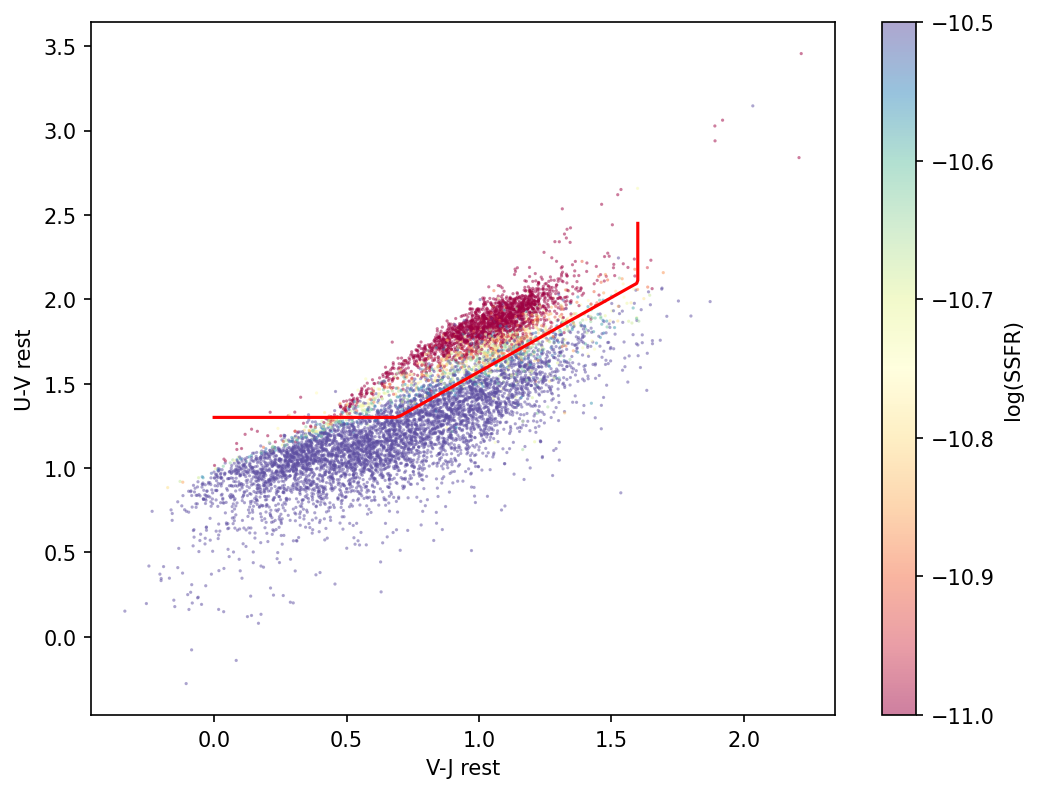

In [75]:
def is_Quiescent(uv,vj):
    return (vj<1.6) & (uv>1.3) & (uv>0.88*vj+0.69)

def is_StarForming(uv,vj):
    return ~(uv>0.88*vj+0.69)
    
# plot the boundary line
vj = np.linspace(0, 2, 100)
uv = 0.88*vj + 0.69
uv = np.maximum(uv, 1.3)  # Ensure uv is at least 1.3
vj = np.minimum(vj, 1.6)  # Ensure vj is at most (uv - 0.69) / 0.88

plt.figure(figsize=(8,6),dpi=150)
plt.plot(vj, uv, color='red', label='Boundary Line')
    
sc = plt.scatter(df_props['vj_colour_50'],df_props['uv_colour_50'], s=0.3, alpha=0.5,c=df_props['ssfr_50'], cmap='Spectral',vmin=-11,vmax=-10.5)
plt.colorbar(sc, label='log(SSFR)')
plt.xlabel('V-J rest')
plt.ylabel('U-V rest')

Text(0.5, 1.0, 'UVJ split')

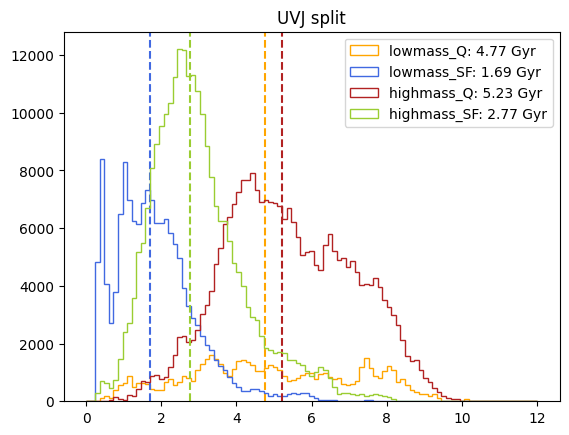

In [76]:
# split by UVJ

lowmass_Q = df_props['stellar_mass_50'].le(10) & is_Quiescent(df_props['uv_colour_50'], df_props['vj_colour_50'])
lowmass_SF = df_props['stellar_mass_50'].le(10) & is_StarForming(df_props['uv_colour_50'], df_props['vj_colour_50'])
highmass_Q = df_props['stellar_mass_50'].gt(10) & is_Quiescent(df_props['uv_colour_50'], df_props['vj_colour_50'])
highmass_SF = df_props['stellar_mass_50'].gt(10) & is_StarForming(df_props['uv_colour_50'], df_props['vj_colour_50'])

names = ["lowmass_Q", "lowmass_SF", "highmass_Q", "highmass_SF"]
colors = ['orange','royalblue','firebrick','yellowgreen']
masks = [lowmass_Q, lowmass_SF, highmass_Q, highmass_SF]

bins = np.linspace(0,12,100)
for mask, name, color in zip(masks, names, colors):
    CID_mask = np.isin(list_of_CIDs, df_props['transient'][mask])
    _sample_means = list_of_age_samples[CID_mask].mean(axis=1)
    
    plt.hist(np.ravel(_sample_means), bins=bins, 
             color=color, histtype='step', label=name+f': {np.median(_sample_means):.2f} Gyr');
    plt.axvline(np.median(_sample_means), color=color, linestyle='--')
plt.legend();
plt.title(f'UVJ split')


In [17]:
np.median(list_of_age_samples)

np.float32(1.857398)

In [18]:
list_of_age_samples.mean()

np.float32(3.4576008)

In [16]:
np.median(list_of_age_samples.mean(axis=1))

np.float32(3.0168314)

Text(0.5, 1.0, 'Q: log(sSFR) <= -11, SF: log(SSFR) > -10.5')

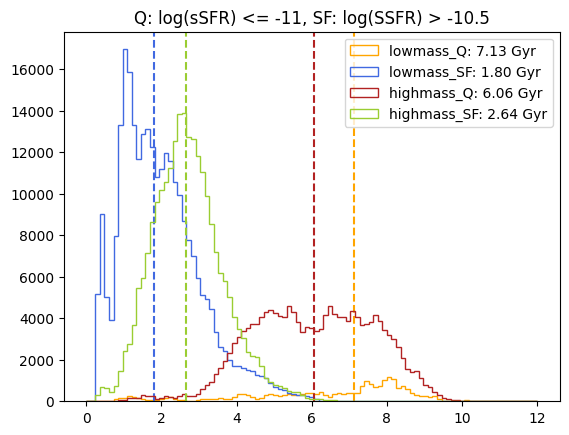

In [77]:
# split by sSFR (intermediate population removed)

lowmass_Q = df_props['stellar_mass_50'].le(10) & df_props['ssfr_50'].le(-11)
lowmass_SF = df_props['stellar_mass_50'].le(10) & df_props['ssfr_50'].gt(-10.5)
highmass_Q = df_props['stellar_mass_50'].gt(10) & df_props['ssfr_50'].le(-11)
highmass_SF = df_props['stellar_mass_50'].gt(10) & df_props['ssfr_50'].gt(-10.5)

names = ["lowmass_Q", "lowmass_SF", "highmass_Q", "highmass_SF"]
colors = ['orange','royalblue','firebrick','yellowgreen']
masks = [lowmass_Q, lowmass_SF, highmass_Q, highmass_SF]

bins = np.linspace(0,12,100)
for mask, name, color in zip(masks, names, colors):
    CID_mask = np.isin(list_of_CIDs, df_props['transient'][mask])
    _sample_means = list_of_age_samples[CID_mask].mean(axis=1)
    
    plt.hist(np.ravel(_sample_means), bins=bins, 
             color=color, histtype='step', label=name+f': {np.median(_sample_means):.2f} Gyr');
    plt.axvline(np.median(_sample_means), color=color, linestyle='--')
plt.legend();
plt.title(f'Q: log(sSFR) <= -11, SF: log(SSFR) > -10.5')

In [78]:
0.03*(6.06-2.64)

0.10259999999999998

In [7]:
list_of_age_samples.mean(axis=2).shape

(8610, 1000)

In [6]:
list_of_age_samples.shape

(8610, 1000, 100)

In [74]:
# compute mean expectation value of age samples and add to df_props
for CID, age in zip(list_of_CIDs, list_of_age_samples.mean(axis=2)):
    df_props.loc[df_props['transient'] == CID, 'prog_age_16'] = np.nanpercentile(age, 16)
    df_props.loc[df_props['transient'] == CID, 'prog_age_50'] = np.median(age)
    df_props.loc[df_props['transient'] == CID, 'prog_age_84'] = np.nanpercentile(age, 84)

In [9]:
df_props.to_csv("host_props_with_SN_age_good_Mar18.csv", index=False)

In [13]:
df_props[df_props['transient'].eq('2024vjb')][['transient','prog_age_16', 'prog_age_50', 'prog_age_84']]

,transient,prog_age_16,prog_age_50,prog_age_84
5374,2024vjb,8.842101,9.605424,10.247384


/tmp/ipykernel_2836032/3754205873.py:4: RankWarning: Polyfit may be poorly conditioned
  coeffs = np.polyfit(df_props['prog_age'][_mask], df_props['mass_weighted_age_50'][_mask], deg=6)
/tmp/ipykernel_2836032/3754205873.py:4: RankWarning: Polyfit may be poorly conditioned
  coeffs = np.polyfit(df_props['prog_age'][_mask], df_props['mass_weighted_age_50'][_mask], deg=6)
/tmp/ipykernel_2836032/3754205873.py:4: RankWarning: Polyfit may be poorly conditioned
  coeffs = np.polyfit(df_props['prog_age'][_mask], df_props['mass_weighted_age_50'][_mask], deg=6)
/tmp/ipykernel_2836032/3754205873.py:4: RankWarning: Polyfit may be poorly conditioned
  coeffs = np.polyfit(df_props['prog_age'][_mask], df_props['mass_weighted_age_50'][_mask], deg=6)
/tmp/ipykernel_2836032/3754205873.py:4: RankWarning: Polyfit may be poorly conditioned
  coeffs = np.polyfit(df_props['prog_age'][_mask], df_props['mass_weighted_age_50'][_mask], deg=6)


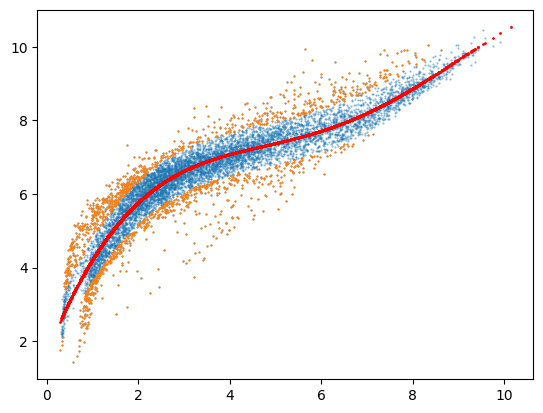

In [81]:
# iteratively fit polynomial with outlier rejection
_mask = np.ones(len(df_props), dtype=bool)
for _ in range(5):
    coeffs = np.polyfit(df_props['prog_age'][_mask], df_props['mass_weighted_age_50'][_mask], deg=6)
    poly = np.poly1d(coeffs)
    residuals = df_props['mass_weighted_age_50'] - poly(df_props['prog_age'])
    std_resid = np.std(residuals[_mask])
    _mask = np.abs(residuals) < 2*std_resid

tprog_to_tmwa = poly(df_props['prog_age'])
plt.scatter(df_props['prog_age'], df_props['mass_weighted_age_50'], s=0.3, alpha=0.5)
plt.scatter(df_props['prog_age'][~_mask], df_props['mass_weighted_age_50'][~_mask], s=0.3, marker='x')
plt.scatter(df_props['prog_age'], tprog_to_tmwa, color='red', label='Polynomial Fit',s=1)

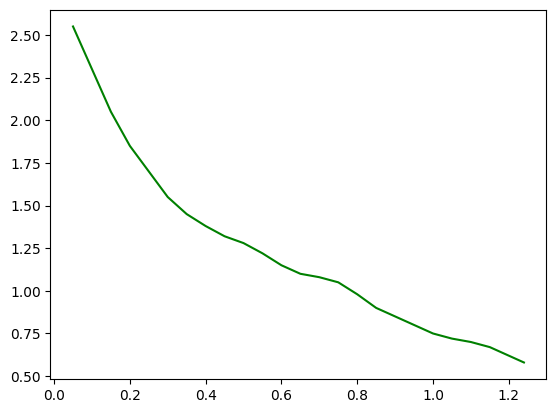

In [82]:
W26_z = [
    0.050, 0.100, 0.150, 0.200, 0.250, 0.300, 0.350, 0.400, 0.450,
    0.500, 0.550, 0.600, 0.650, 0.700, 0.750, 0.800, 0.850, 0.900,
    0.950, 1.000, 1.050, 1.100, 1.150, 1.200, 1.240
]

W26_age_gyr = [
    2.55, 2.30, 2.05, 1.85, 1.70, 1.55, 1.45, 1.38, 1.32,
    1.28, 1.22, 1.15, 1.10, 1.08, 1.05, 0.98, 0.90, 0.85,
    0.80, 0.75, 0.72, 0.70, 0.67, 0.62, 0.58
]
W26_z = np.array(W26_z)
W26_age_gyr = np.array(W26_age_gyr)
plt.plot(W26_z, W26_age_gyr, color='green', label='W26 Age-Z Relation')

In [40]:
np.argmin(np.abs(W26_age_gyr-1))

TypeError: unsupported operand type(s) for -: 'list' and 'int'

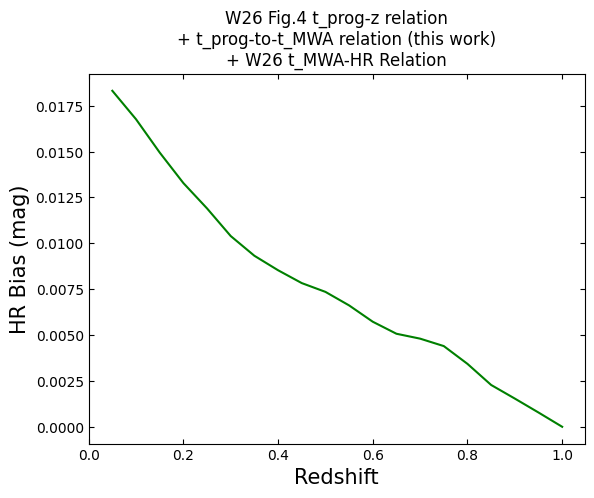

In [83]:
HR_bias = np.array(poly(W26_age_gyr)*0.007)
HR_bias -= HR_bias[np.argmin(np.abs(W26_z-1))]
HR_bias[W26_z>1] = np.nan
plt.plot(W26_z, HR_bias, color='green', label='')
plt.xlim(0,)
plt.xlabel('Redshift', fontsize=15)
plt.ylabel('HR Bias (mag)',fontsize=15)
plt.title('W26 Fig.4 t_prog-z relation\n+ t_prog-to-t_MWA relation (this work)\n+ W26 t_MWA-HR Relation')
plt.gca().tick_params(direction='in',top=True,right=True)

/tmp/ipykernel_2836032/1631050479.py:24: UserWarning: You passed a edgecolor/edgecolors ('yellowgreen') for an unfilled marker ('+').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(df_props['mass_weighted_age_50'][mask], df_props['prog_age'][mask], s=ms,
/tmp/ipykernel_2836032/1631050479.py:26: UserWarning: You passed a edgecolor/edgecolors ('yellowgreen') for an unfilled marker ('+').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax_bot.scatter(df_props['mass_weighted_age_50'][mask],


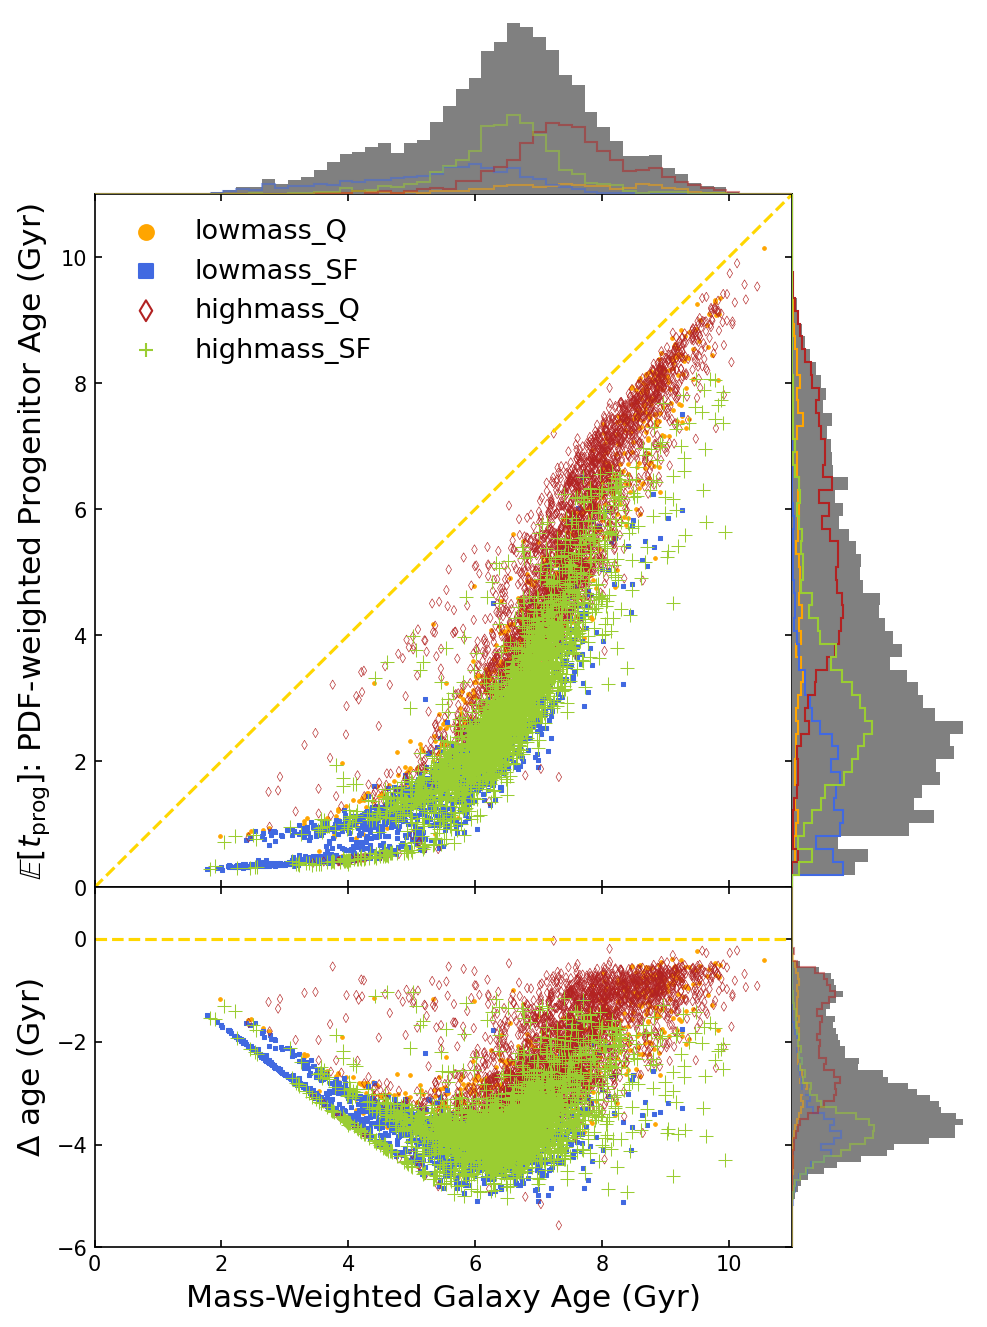

In [21]:
df_props['age_diff'] = df_props['prog_age'] - df_props['mass_weighted_age_50']

fig,ax = plt.subplots(1,1,figsize=(6,6),dpi=150)
pos = ax.get_position().bounds
ax_bot = fig.add_axes([pos[0], pos[1]-0.4, pos[2], 0.4])
ax_top = fig.add_axes([pos[0], pos[1]+pos[3], pos[2], 0.2])
ax_right = fig.add_axes([pos[0]+pos[2], pos[1], 0.2, pos[3]])
ax_botright = fig.add_axes([pos[0]+pos[2], pos[1]-0.4, 0.2, 0.4])


# histograms
age_bins = np.linspace(0,12,60)
diff_bins = np.linspace(-6,1,60)
ax_right.hist(df_props['prog_age'], bins=age_bins, orientation='horizontal', color='gray')
ax_top.hist(df_props['mass_weighted_age_50'], bins=age_bins, color='gray')
ax_botright.hist(df_props['age_diff'], bins=diff_bins, color='gray',orientation='horizontal')

for mask, name, color,marker,ms,noFC,lw in zip(
    masks, names, colors, 
    ['o','s','d','+'], 
    [3,3,10,50],
    [False,False,True,False],
    [0.5,0.5,0.3,0.5]):
    ax.scatter(df_props['mass_weighted_age_50'][mask], df_props['prog_age'][mask], s=ms, 
                alpha=1, label=name, ec=color, fc='none' if noFC else color, marker=marker, lw=lw)
    ax_bot.scatter(df_props['mass_weighted_age_50'][mask], 
                   df_props['age_diff'][mask], s=ms,
                alpha=1, label=name, ec=color, fc='none' if noFC else color, marker=marker, lw=lw)
    
    # add histograms of each population to the marginal axes
    ax_right.hist(df_props['prog_age'][mask], bins=age_bins, orientation='horizontal', color=color, histtype='step')
    ax_top.hist(df_props['mass_weighted_age_50'][mask], bins=age_bins, color=color, alpha=0.5, histtype='step')
    ax_botright.hist(df_props['age_diff'][mask], bins=diff_bins, color=color, alpha=0.5, orientation='horizontal', histtype='step')
    
    
leg = ax.legend(frameon=False, fontsize=13)
# set marker size in legend
for handle in leg.legend_handles:
    handle.set_sizes([50])
    handle.set_linewidth(1)

ax.set_ylabel(r'$\mathbb{E}[t_\mathrm{prog}]$: PDF-weighted Progenitor Age (Gyr)', fontsize=15)
ax_bot.set_xlabel('Mass-Weighted Galaxy Age (Gyr)', fontsize=15)
ax_bot.set_ylabel(r'$\Delta$ age (Gyr)', fontsize=15)
ax.plot([0,12],[0,12],c='gold',ls='--')
ax.set_ylim(0,11)
ax.set_xlim(0,11)
ax.tick_params(direction='in', top=True, right=True)
ax.set_xticklabels([])


ax_top.axis('off')
ax_right.axis('off')
ax_botright.axis('off')
ax_top.set_xlim(ax.get_xlim())
ax_right.set_ylim(ax.get_ylim())
ax_bot.set_xlim(ax.get_xlim())
ax_bot.set_ylim(-6,1)
ax_botright.set_ylim(-6,1)
ax_bot.set_yticks(np.arange(-6,1,2))
ax_bot.tick_params(direction='in', top=True, right=True)
ax_bot.axhline(0, c='gold', ls='--')
# plt.scatter(df_props['prog_age'], df_props['mass_weighted_age_50'], s=1, alpha=0.5,)